# Replicate Retrieval Violins

This notebook reads the precomputed within-dataset strict retrieval outputs and plots per-dataset violins of observed normalized ranks, using cosine similarity on `logFC` signatures. Black points show condition scores; red crosses show centroid baseline scores. Summary tables report observed and baseline means/medians.

Each score uses all available conditions independently. Summary and heatmap deltas average the saved paired observed-minus-centroid differences, not differences of means.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

def find_repo_root(start=None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "results").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root from the current working directory.")


REPO_ROOT = find_repo_root()
RESULTS_DIR = REPO_ROOT / "results" / "replicate_signature_similarity_sep_rep"
OUTPUT_DIR = RESULTS_DIR

# Select one combination; never pool representations or similarity metrics.
SIMILARITY_METRIC = "cosine"  # cosine, spearman, or l2 (negative Euclidean distance)
SCALE_VARIANT = "raw"  # raw, per_gene_population_zscore_dataset,
                       # or per_gene_population_zscore_dataset_cell_type
SCALE_LABELS = {
    "raw": "logFC",
    "per_gene_population_zscore_dataset": "dataset z-score(logFC)",
    "per_gene_population_zscore_dataset_cell_type": "dataset/cell-type z-score(logFC)",
}

DATASET_ORDER = [
    "cigs_mce",
    "cigs_tcm",
    "dilimap_train_val",
    "gdpx2",
    
    
    "l1000_phase1",
    "l1000_phase2",
    
    "novartis_batch_2500",
    "op3",
    "sciplex",
    "tahoe",
    "vcpi_0001",
    "vcpi_0002",
    
    
    
]

PRETTY_LABELS = {
    "l1000_phase1": "L1000 Phase I",
    "l1000_phase2": "L1000 Phase II",
    "tahoe": "Tahoe-100M",
    "cigs_mce": "CIGS-MCE",
    "novartis_batch_2500": "Novartis/DRUG-seq U2OS",
    "vcpi_0001": "VCPI-0001",
    "cigs_tcm": "CIGS-TCM",
    "vcpi_0002": "VCPI-0002",
    "gdpx2": "GDPx2",
    "sciplex": "sci-Plex",
    "dilimap_train_val": "DILImap",
    "op3": "OP3",
}

DATASET_ORDER_MAP = {dataset_name: idx for idx, dataset_name in enumerate(DATASET_ORDER)}

sns.set_theme(style="whitegrid", context="talk")

def pretty_label(dataset_name: str) -> str:
    return PRETTY_LABELS.get(str(dataset_name), str(dataset_name))


def dataset_names_in_order(frame: pd.DataFrame) -> list[str]:
    present = set(frame["dataset_name"].dropna().astype(str).unique().tolist())
    ordered = [dataset_name for dataset_name in DATASET_ORDER if dataset_name in present]
    ordered.extend(sorted(dataset_name for dataset_name in present if dataset_name not in DATASET_ORDER_MAP))
    return ordered


def dataset_label_order(frame: pd.DataFrame) -> list[str]:
    return [pretty_label(dataset_name) for dataset_name in dataset_names_in_order(frame)]


def sort_by_dataset_order(frame: pd.DataFrame) -> pd.DataFrame:
    sort_frame = frame.copy()
    sort_frame["_dataset_order"] = sort_frame["dataset_name"].astype(str).map(DATASET_ORDER_MAP).fillna(len(DATASET_ORDER))
    return (
        sort_frame.sort_values(["_dataset_order", "dataset_name"])
        .drop(columns="_dataset_order")
        .reset_index(drop=True)
    )


RETRIEVAL_COLUMNS = [
    "dataset_name", "condition_key", "similarity_metric", "scale_variant",
    "observed_normalized_rank", "centroid_normalized_rank", "observed_minus_centroid",
]


def select_retrieval_summary(frame, *, similarity_metric, scale_variant):
    missing = sorted(set(RETRIEVAL_COLUMNS) - set(frame.columns))
    if missing:
        raise KeyError(f"Missing columns in condition_retrieval_summary.tsv: {missing}")
    selected = frame.loc[
        frame["similarity_metric"].eq(similarity_metric)
        & frame["scale_variant"].eq(scale_variant)
    ].copy()
    if selected.empty:
        available = frame[["scale_variant", "similarity_metric"]].drop_duplicates()
        raise ValueError(
            f"No retrieval rows for scale={scale_variant!r}, metric={similarity_metric!r}. "
            f"Available combinations: {available.to_dict('records')}"
        )
    if selected[["dataset_name", "condition_key"]].isna().any().any():
        raise ValueError("Retrieval rows must have dataset_name and condition_key.")
    if selected.duplicated(["dataset_name", "condition_key"]).any():
        raise ValueError("Expected one row per dataset and condition after selecting a scale and metric.")
    return selected


In [2]:
def plot_violin_with_baseline(frame: pd.DataFrame, *, observed_col: str, baseline_col: str, centroid_delta_col: str, title: str, ylabel: str, pdf_name: str) -> pd.DataFrame:
    required_columns = {"dataset_name", "condition_key", observed_col, baseline_col, centroid_delta_col}
    missing = sorted(required_columns - set(frame.columns))
    if missing:
        raise KeyError(f"Missing columns for plot {title!r}: {missing}")

    plot_frame = frame[["dataset_name", "condition_key", observed_col, baseline_col, centroid_delta_col]].copy()
    plot_frame = plot_frame.rename(columns={observed_col: "observed", baseline_col: "baseline", centroid_delta_col: "delta_centroid"})
    plot_frame["dataset_label"] = plot_frame["dataset_name"].map(pretty_label)
    # Keep observed and centroid scores independently, including baseline-only rows.
    observed_frame = plot_frame.loc[plot_frame["observed"].notna()].copy()
    if observed_frame.empty:
        raise ValueError(f"No observed values available for plot {title!r}.")

    order = dataset_label_order(plot_frame)
    fig_width = max(10.0, 1.15 * len(order) + 2.0)
    fig, ax = plt.subplots(figsize=(fig_width, 6.4))

    sns.violinplot(
        data=observed_frame,
        x="dataset_label",
        y="observed",
        order=order,
        inner=None,
        cut=0,
        linewidth=1.0,
        color="#dbe9f6",
        ax=ax,
    )

    x_lookup = {label: idx for idx, label in enumerate(order)}
    rng = np.random.default_rng(0)
    observed_x = np.array([x_lookup[label] - 0.10 for label in observed_frame["dataset_label"]], dtype=float)
    observed_x += rng.uniform(-0.08, 0.08, size=len(observed_frame))
    ax.scatter(observed_x, observed_frame["observed"], s=18, alpha=0.45, color="black", zorder=5)

    baseline_frame = plot_frame.loc[plot_frame["baseline"].notna()].copy()
    baseline_count_by_dataset = baseline_frame.groupby("dataset_name")["condition_key"].nunique() if not baseline_frame.empty else pd.Series(dtype=int)
    if not baseline_frame.empty:
        baseline_x = np.array([x_lookup[label] + 0.17 for label in baseline_frame["dataset_label"]], dtype=float)
        baseline_x += rng.uniform(-0.04, 0.04, size=len(baseline_frame))
        ax.scatter(
            baseline_x,
            baseline_frame["baseline"],
            s=42,
            alpha=0.95,
            marker="x",
            linewidths=1.5,
            color="#c83e4d",
            zorder=6,
        )

    summary = (
        plot_frame.groupby(["dataset_name", "dataset_label"], as_index=False)
        .agg(
            n_conditions=("condition_key", "nunique"),
            observed_mean=("observed", "mean"),
            observed_median=("observed", "median"),
            baseline_mean=("baseline", "mean"),
            baseline_median=("baseline", "median"),
            # Average the saved paired differences, never subtract dataset means.
            delta_centroid=("delta_centroid", "mean"),
        )
    )
    summary = sort_by_dataset_order(summary)
    observed_counts = observed_frame.groupby("dataset_name")["condition_key"].nunique()
    summary["n_conditions_with_observed"] = summary["dataset_name"].map(observed_counts).fillna(0).astype(int)
    summary["n_conditions_with_baseline"] = summary["dataset_name"].map(baseline_count_by_dataset).fillna(0).astype(int)

    for _, row in summary.iterrows():
        x = x_lookup[row["dataset_label"]]
        if pd.notna(row["observed_mean"]):
            ax.scatter(x - 0.16, row["observed_mean"], marker="D", s=62, color="#1f77b4", zorder=7)
        if pd.notna(row["observed_median"]):
            ax.scatter(x - 0.16, row["observed_median"], marker="s", s=58, color="#2ca02c", zorder=7)
        if pd.notna(row["baseline_mean"]):
            ax.scatter(x + 0.23, row["baseline_mean"], marker="^", s=68, color="#c83e4d", zorder=7)

    handles = [
        Line2D([], [], linestyle="", marker="o", color="black", markersize=5, alpha=0.6, label="Observed condition"),
        Line2D([], [], linestyle="", marker="x", color="#c83e4d", markersize=7, label="Centroid condition"),
        Line2D([], [], linestyle="", marker="D", color="#1f77b4", markersize=7, label="Observed mean"),
        Line2D([], [], linestyle="", marker="s", color="#2ca02c", markersize=7, label="Observed median"),
        Line2D([], [], linestyle="", marker="^", color="#c83e4d", markersize=7, label="Centroid mean"),
    ]
    ax.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.01),
              ncol=5, fontsize=12, frameon=False)
    ax.set_title(title, pad=48)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.set_ylim(-0.05, 1.05)
    ax.tick_params(axis="x", rotation=35)
    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
    sns.despine(ax=ax)
    fig.tight_layout()
    out_path = OUTPUT_DIR / pdf_name
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    print(f"Saved plot to {out_path}")
    zero_baseline = summary.loc[summary["n_conditions_with_baseline"] == 0, "dataset_label"].tolist()
    if zero_baseline:
        print("No baseline-scored conditions in:", ", ".join(zero_baseline))
    display(summary)
    return summary



In [3]:
def plot_summary_heatmap(
    summary: pd.DataFrame,
    *,
    title: str,
    value_label: str,
    pdf_name: str,
    vmin=None,
    vmax=None,
    show_colorbar: bool = True,
    show_dataset_labels: bool = True,
) -> pd.DataFrame:
    columns = {
        "observed_mean": "Observed",
        "baseline_mean": "Centroid baseline",
        "delta_centroid": r"$\Delta$ centroid",
    }
    missing = sorted({"dataset_name", "dataset_label", *columns} - set(summary.columns))
    if missing:
        raise KeyError(f"Missing columns for heatmap {title!r}: {missing}")
    summary_frame = sort_by_dataset_order(summary)
    heatmap_frame = (
        summary_frame.set_index("dataset_label")[list(columns)]
        .rename(columns=columns)
        .rename_axis("Dataset")
    )
    fig, ax = plt.subplots(figsize=(8.6, max(4.5, 1.0 * len(heatmap_frame))))
    sns.heatmap(
        heatmap_frame,
        annot=True,
        fmt=".3f",
        cmap="RdBu_r",
        center=0.0,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        linecolor="white",
        cbar=show_colorbar,
        cbar_kws={"label": value_label} if show_colorbar else {},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    if show_dataset_labels:
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    else:
        ax.tick_params(axis="y", labelleft=False, length=0)
    fig.tight_layout()
    out_path = OUTPUT_DIR / pdf_name
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    print(f"Saved heatmap to {out_path}")
    display(heatmap_frame)
    return heatmap_frame


In [4]:
condition_retrieval_summary = pd.read_csv(
    RESULTS_DIR / "condition_retrieval_summary.tsv",
    sep="\t",
    usecols=lambda column: column in RETRIEVAL_COLUMNS,
    dtype={"dataset_name": "string", "condition_key": "string"},
)
condition_retrieval_summary = select_retrieval_summary(
    condition_retrieval_summary,
    similarity_metric=SIMILARITY_METRIC,
    scale_variant=SCALE_VARIANT,
)
representation_label = SCALE_LABELS.get(SCALE_VARIANT, SCALE_VARIANT)
output_stem = f"replicate_retrieval_{SCALE_VARIANT}_{SIMILARITY_METRIC}"
print(
    f"Loaded {len(condition_retrieval_summary):,} condition rows across "
    f"{condition_retrieval_summary['dataset_name'].nunique():,} datasets "
    f"for {representation_label}, {SIMILARITY_METRIC}."
)
condition_retrieval_summary.head()


Loaded 84,200 condition rows across 12 datasets for logFC, cosine.


,dataset_name,condition_key,similarity_metric,scale_variant,observed_normalized_rank,centroid_normalized_rank,observed_minus_centroid
0,dilimap_train_val,CL_0000182|11033|24|1000,cosine,raw,0.999866,0.999332,5.341613e-04
1,dilimap_train_val,CL_0000182|11033|24|111,cosine,raw,0.994523,0.983240,1.128363e-02
2,dilimap_train_val,CL_0000182|11033|24|333,cosine,raw,0.999532,0.999533,-9.365148e-08
3,dilimap_train_val,CL_0000182|11033|24|37,cosine,raw,0.998464,0.997796,6.674273e-04
4,dilimap_train_val,CL_0000182|11333|24|1000,cosine,raw,1.000000,0.937700,6.229968e-02


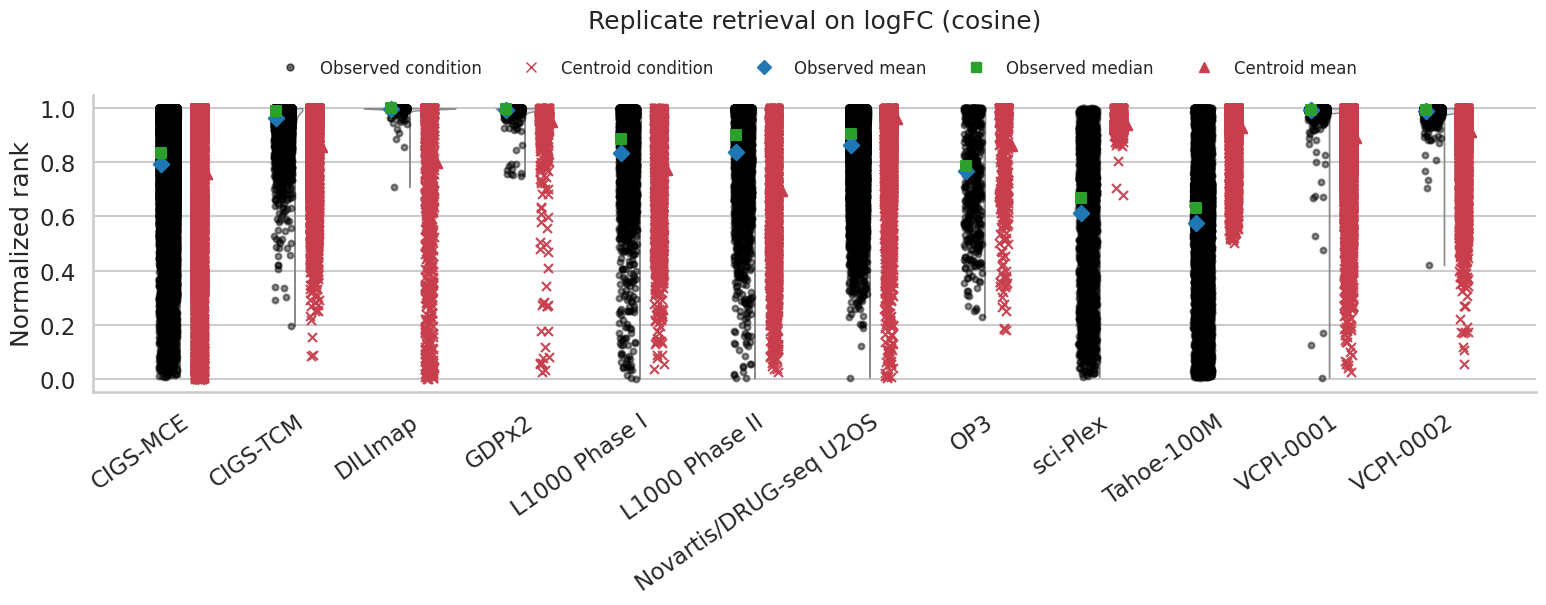

Saved plot to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/replicate_retrieval_raw_cosine_violin.pdf


,dataset_name,dataset_label,n_conditions,observed_mean,observed_median,baseline_mean,baseline_median,delta_centroid,n_conditions_with_observed,n_conditions_with_baseline
0,cigs_mce,CIGS-MCE,21426,0.791949,0.836109,0.761289,0.904151,0.030659,21426,21426
1,cigs_tcm,CIGS-TCM,7020,0.963469,0.988675,0.861723,0.902680,0.101746,7020,7020
2,dilimap_train_val,DILImap,1184,0.997431,0.999733,0.799310,0.958216,0.198105,1184,1176
3,gdpx2,GDPx2,2064,0.994099,0.997646,0.953817,0.967055,0.040282,2064,2064
4,l1000_phase1,L1000 Phase I,2517,0.833939,0.887439,0.775507,0.822903,0.059502,2517,2437
5,l1000_phase2,L1000 Phase II,2614,0.837594,0.899668,0.699028,0.717191,0.138487,2614,2612
6,novartis_batch_2500,Novartis/DRUG-seq U2OS,15276,0.865184,0.904124,0.964740,0.992477,-0.099555,15276,15276
7,op3,OP3,541,0.769341,0.785948,0.863428,0.951100,-0.094088,541,541
8,sciplex,sci-Plex,2224,0.611299,0.669492,0.942081,0.938301,-0.330782,2224,2224
9,tahoe,Tahoe-100M,7226,0.577245,0.631988,0.932195,0.966154,-0.354949,7226,7226


In [5]:
retrieval_summary = plot_violin_with_baseline(
    condition_retrieval_summary,
    observed_col="observed_normalized_rank",
    baseline_col="centroid_normalized_rank",
    centroid_delta_col="observed_minus_centroid",
    title=f"Replicate retrieval on {representation_label} ({SIMILARITY_METRIC})",
    ylabel="Normalized rank",
    pdf_name=f"{output_stem}_violin.pdf",
)


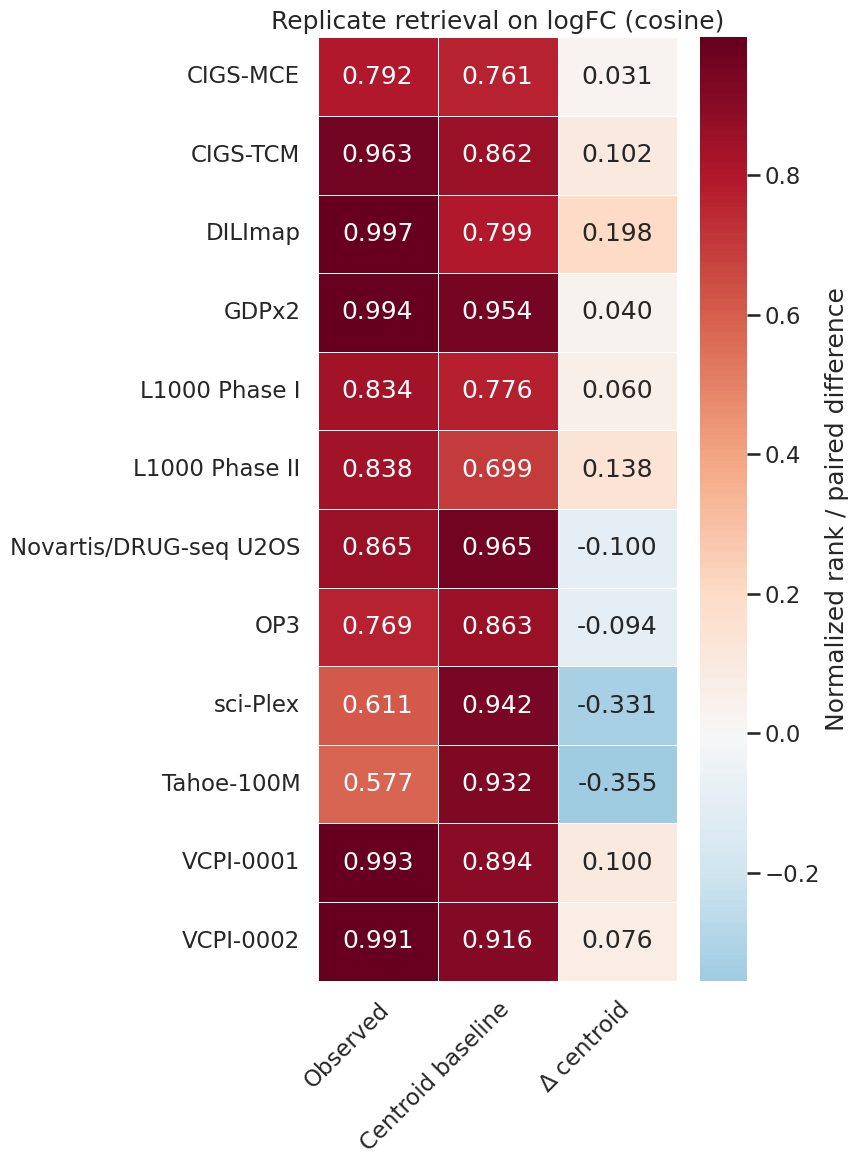

Saved heatmap to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/replicate_retrieval_raw_cosine_heatmap.pdf


,Observed,Centroid baseline,$\Delta$ centroid
Dataset,,,
CIGS-MCE,0.791949,0.761289,0.030659
CIGS-TCM,0.963469,0.861723,0.101746
DILImap,0.997431,0.799310,0.198105
GDPx2,0.994099,0.953817,0.040282
L1000 Phase I,0.833939,0.775507,0.059502
L1000 Phase II,0.837594,0.699028,0.138487
Novartis/DRUG-seq U2OS,0.865184,0.964740,-0.099555
OP3,0.769341,0.863428,-0.094088
sci-Plex,0.611299,0.942081,-0.330782


In [6]:
retrieval_heatmap = plot_summary_heatmap(
    retrieval_summary,
    title=f"Replicate retrieval on {representation_label} ({SIMILARITY_METRIC})",
    value_label="Normalized rank / paired difference",
    pdf_name=f"{output_stem}_heatmap.pdf",
)
